<a href="https://colab.research.google.com/github/Venkat-267-byte/Deep-Learning-/blob/main/Skill/Skill%205.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pycocotools -q

import json
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
uploaded = files.upload()

json_file = list(uploaded.keys())[0]

with open(json_file, "r") as f:
    coco_data = json.load(f)

print("COCO annotation file loaded successfully!")
print("Available sections:", coco_data.keys())

Saving annotations.json to annotations.json
COCO annotation file loaded successfully!
Available sections: dict_keys(['images', 'categories', 'annotations'])


In [10]:
print("COCO JSON STRUCTURE")
print("==================")

print("Images:", len(coco_data.get("images", [])))
print("Annotations:", len(coco_data.get("annotations", [])))
print("Categories:", len(coco_data.get("categories", [])))

print("\nFirst Image Record:")
print(coco_data["images"][0])

print("\nFirst Annotation Record:")
print(coco_data["annotations"][0])

print("\nFirst Category Record:")
print(coco_data["categories"][0])

COCO JSON STRUCTURE
Images: 1
Annotations: 11
Categories: 5

First Image Record:
{'id': 1, 'file_name': 'Hyderabad Rush Hour Crossing.png', 'width': 1672, 'height': 941}

First Annotation Record:
{'id': 1, 'image_id': 1, 'category_id': 2, 'bbox': [610, 335, 510, 375], 'area': 191250, 'iscrowd': 0}

First Category Record:
{'id': 1, 'name': 'person'}


In [11]:
categories = coco_data["categories"]

print("COCO CATEGORIES")
print("================")

for category in categories:
    print(
        "Category ID:", category["id"],
        "| Class Name:", category["name"]
    )

COCO CATEGORIES
Category ID: 1 | Class Name: person
Category ID: 2 | Class Name: car
Category ID: 3 | Class Name: bus
Category ID: 4 | Class Name: motorcycle
Category ID: 5 | Class Name: auto_rickshaw


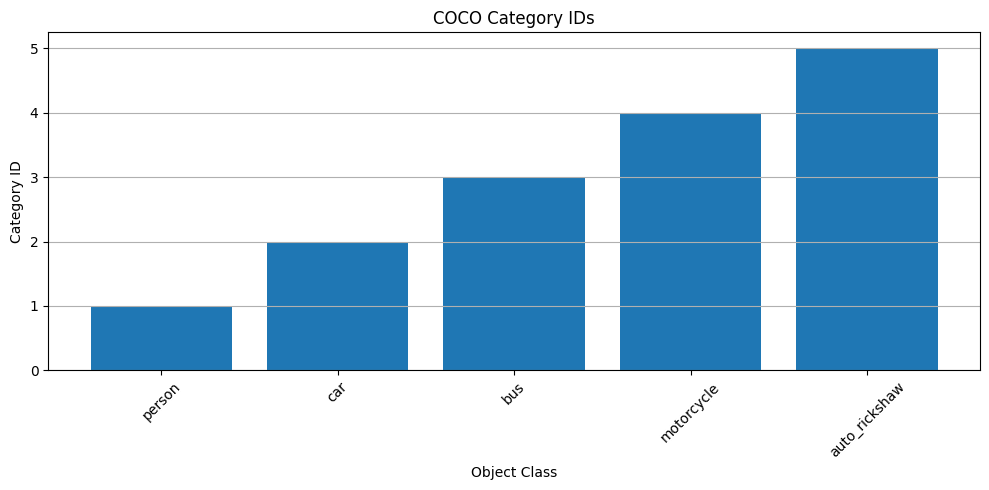

In [12]:
category_ids = [c["id"] for c in categories]
category_names = [c["name"] for c in categories]

plt.figure(figsize=(10, 5))
plt.bar(category_names, category_ids)

plt.title("COCO Category IDs")
plt.xlabel("Object Class")
plt.ylabel("Category ID")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [13]:
images = coco_data["images"]

print("TOTAL IMAGES:", len(images))
print("\nIMAGE RECORDS")
print("================")

for img in images[:10]:
    print(
        "Image ID:", img["id"],
        "| File Name:", img["file_name"],
        "| Width:", img["width"],
        "| Height:", img["height"]
    )

TOTAL IMAGES: 1

IMAGE RECORDS
Image ID: 1 | File Name: Hyderabad Rush Hour Crossing.png | Width: 1672 | Height: 941


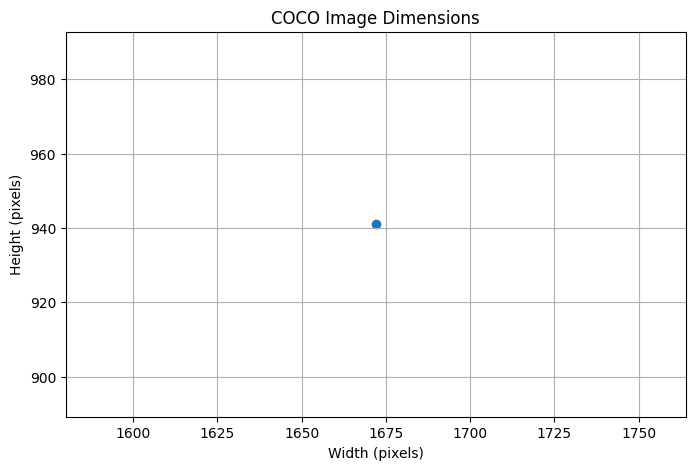

In [14]:
widths = [img["width"] for img in images]
heights = [img["height"] for img in images]

plt.figure(figsize=(8, 5))
plt.scatter(widths, heights)

plt.title("COCO Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.grid(True)
plt.show()

In [15]:
print("Upload the image files referenced in your COCO JSON.")
uploaded_images = files.upload()

image_folder = "/content/coco_images"
os.makedirs(image_folder, exist_ok=True)

for filename, content in uploaded_images.items():
    path = os.path.join(image_folder, filename)

    with open(path, "wb") as f:
        f.write(content)

print("Images uploaded successfully!")
print("Number of uploaded images:", len(uploaded_images))

Upload the image files referenced in your COCO JSON.


Saving Screenshot 2026-11-11 104734.png to Screenshot 2026-11-11 104734 (2).png
Images uploaded successfully!
Number of uploaded images: 1


In [16]:
# Create category ID to class name mapping
category_map = {
    category["id"]: category["name"]
    for category in coco_data["categories"]
}

# Create image ID to image details mapping
image_map = {
    image["id"]: image
    for image in coco_data["images"]
}

# Select an uploaded image which exists in the JSON
selected_image = None

for img in coco_data["images"]:
    image_path = os.path.join(image_folder, img["file_name"])

    if os.path.exists(image_path):
        selected_image = img
        break

if selected_image is None:
    print("No matching uploaded image found.")
else:
    image_path = os.path.join(
        image_folder, selected_image["file_name"]
    )

    image = Image.open(image_path).convert("RGB")

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)

    # Find annotations belonging to this image
    image_annotations = [
        ann for ann in coco_data["annotations"]
        if ann["image_id"] == selected_image["id"]
    ]

    for ann in image_annotations:
        x, y, w, h = ann["bbox"]
        category_id = ann["category_id"]
        label = category_map.get(category_id, "Unknown")

        # Draw bounding box
        rectangle = patches.Rectangle(
            (x, y), w, h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        # Add class label
        ax.text(
            x, y,
            label,
            color="white",
            fontsize=10,
            backgroundcolor="red"
        )

    ax.set_title(
        f"Image ID: {selected_image['id']} | "
        f"Annotations: {len(image_annotations)}"
    )

    ax.axis("off")
    plt.show()

    print("Image ID:", selected_image["id"])
    print("File Name:", selected_image["file_name"])
    print("Number of annotations:", len(image_annotations))

No matching uploaded image found.


In [17]:
valid_image_ids = set(image_map.keys())
valid_category_ids = set(category_map.keys())

valid_annotations = 0
invalid_annotations = 0

for ann in coco_data["annotations"]:
    image_id = ann["image_id"]
    category_id = ann["category_id"]
    x, y, w, h = ann["bbox"]

    image_info = image_map.get(image_id)

    if image_info is None or category_id not in valid_category_ids:
        invalid_annotations += 1
        continue

    # Check if bounding box is within image boundaries
    if (
        x >= 0 and y >= 0 and w > 0 and h > 0
        and x + w <= image_info["width"]
        and y + h <= image_info["height"]
    ):
        valid_annotations += 1
    else:
        invalid_annotations += 1

print("ANNOTATION VERIFICATION")
print("=====================")
print("Total annotations:", len(coco_data["annotations"]))
print("Valid annotations:", valid_annotations)
print("Invalid annotations:", invalid_annotations)

if invalid_annotations == 0:
    print("All annotations passed the checks!")
else:
    print("Some annotations need inspection.")

ANNOTATION VERIFICATION
Total annotations: 11
Valid annotations: 11
Invalid annotations: 0
All annotations passed the checks!


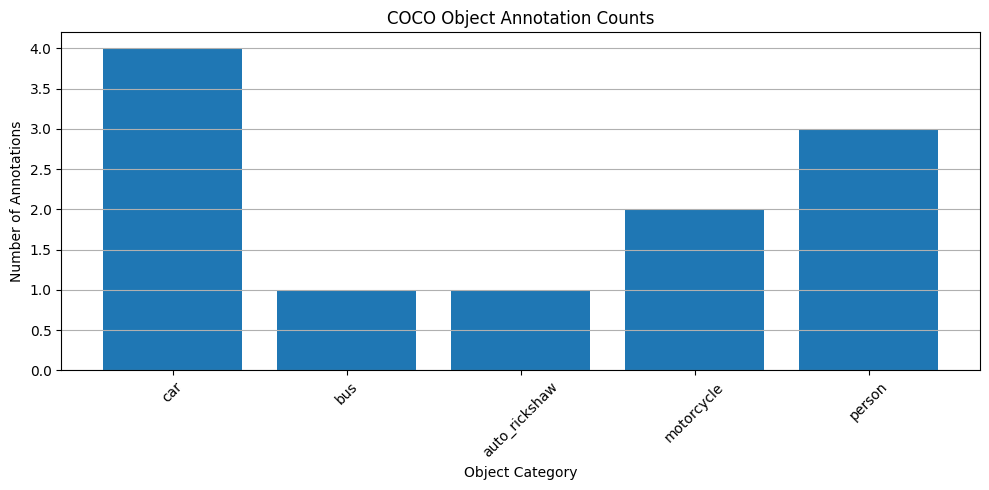

Annotation counts by category:
car : 4
bus : 1
auto_rickshaw : 1
motorcycle : 2
person : 3


In [18]:
from collections import Counter

class_counts = Counter()

for ann in coco_data["annotations"]:
    category_name = category_map.get(
        ann["category_id"], "Unknown"
    )
    class_counts[category_name] += 1

plt.figure(figsize=(10, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("COCO Object Annotation Counts")
plt.xlabel("Object Category")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("Annotation counts by category:")
for name, count in class_counts.items():
    print(name, ":", count)